In [47]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel


class State(BaseModel):
    message: str = ''
    
    


def node_1 (state: State) -> State:
    return state


def node_2 (state: State) -> State:
    state.message = f'{state.message}' + 'happy!'
    return state


def node_3 (state: State) -> State:
    state.message = f'{state.message} ' + 'sad'
    return state




In [58]:
import random



def condition_maker (state: State) :
    
    if random.random()>0.5:
        return "node_2"
    
    return "node_3"

In [59]:
graph = StateGraph(State)


graph.add_node("node1", node_1)
graph.add_node("node2", node_2)
graph.add_node("node3", node_3)


graph.add_edge(START, "node1")
graph.add_conditional_edges("node1", condition_maker,
                            {"node_2": "node2", "node_3": "node3"})

graph.add_edge("node2", END)
graph.add_edge("node3", END)


graph= graph.compile()

print(graph)

In [50]:
from IPython.display import Image, display


res = graph.invoke({
    "message": "Hello i'm rayan and i'm "})

print(res)


{'message': "Hello i'm rayan and i'm happy!"}


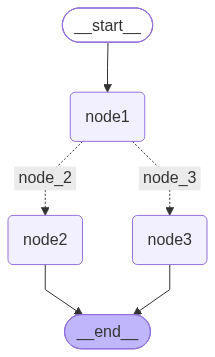

In [60]:
display(Image(graph.get_graph().draw_mermaid_png()))